In [1]:
import numpy as np
import polars as pl
import matplotlib.pyplot as plt
import polars.selectors as cs
import math
import seaborn as sns
from pathlib import Path

In [2]:
def clean(d: pl.DataFrame) -> pl.DataFrame:
    bad = [c for c in d.columns if c == "" or c.startswith("Unnamed")]
    return d.drop(bad)

dataset_path = Path('../data/glint')
df_list = []

for f in sorted(dataset_path.iterdir()):
    if f.is_file() and f.suffix == '.csv':
        d = pl.read_csv(f, separator=';', infer_schema_length=None)
        d = clean(d).with_columns(pl.lit('glint').alias('dataset'))
        df_list.append(d)

tono = pl.read_csv(
    '../data/tono/ofiq_tono_completo.csv',
    separator=',',
    infer_schema_length=None,
    truncate_ragged_lines=True,
)
tono = clean(tono).with_columns(pl.lit('tono').alias('dataset'))
df_list.append(tono)

cols = df_list[0].columns
for d in df_list:
    if set(d.columns) != set(cols):
        print("colonne diverse:", set(d.columns) ^ set(cols))
df_list = [d.select(cols) for d in df_list]

df = pl.concat(df_list, how='vertical_relaxed')
df.shape

(33791, 59)

#### OFIQ Columns

| Column | Description |
|---|---|
| `Filename` | Path to the analyzed image |
| `assessment_time_in_ms` | Image processing time, in milliseconds |
| `UnifiedQualityScore` | Overall score produced by a CNN (MagFace) measuring the image's suitability for face recognition |
| `BackgroundUniformity` | Background uniformity: mean of the squared luminance gradients across the background |
| `IlluminationUniformity` | Illumination uniformity: intersection of the luminance histograms of the left and right cheeks |
| `LuminanceMean` | Mean luminance within the face region |
| `LuminanceVariance` | Luminance variance within the face region |
| `UnderExposurePrevention` | Proportion of non-occluded face pixels with very low luminance (0–25), i.e. underexposed pixels |
| `OverExposurePrevention` | Proportion of non-occluded face pixels with very high luminance (247–255), i.e. overexposed pixels |
| `DynamicRange` | Dynamic range: entropy of the normalized luminance histogram within the face region |
| `Sharpness` | Sharpness: output of a Random Forest applied to Sobel and Laplace filters |
| `CompressionArtifacts` | Compression artifacts: PSNR estimated by a CNN relative to an uncompressed source |
| `NaturalColour` | Colour naturalness: skin colour in CIELAB space, measured in the cheek regions |
| `SingleFacePresent` | Presence of a single face in the image |
| `EyesOpen` | Eye openness: maximum distance between the upper and lower eyelids, divided by the distance between the eye centres and the chin |
| `MouthClosed` | Mouth closure: mouth opening divided by the distance between the eye centres and the chin |
| `EyesVisible` | Eye visibility: proportion of the eye region that is occluded |
| `MouthOcclusionPrevention` | Proportion of the mouth region that is occluded |
| `FaceOcclusionPrevention` | Proportion of the face region marked as occluded |
| `InterEyeDistance` | Distance between the eyes, corrected for perspective distortion caused by head pose |
| `HeadSize` | Head size: distance between the eye centres and the chin relative to the image height |
| `LeftwardCropOfTheFaceImage` | Leftward face cropping: position of the right eye centre relative to the inter-eye distance |
| `RightwardCropOfTheFaceImage` | Rightward face cropping: position of the left eye centre relative to the inter-eye distance and image width |
| `MarginAboveTheFace` | Margin above the face: distance between the eye centres and the top edge of the image, relative to the vertical face size |
| `MarginBelowTheFace` | Margin below the face: distance between the chin and the bottom edge of the image, relative to the vertical face size |
| `HeadPoseYaw` | Horizontal head rotation (left/right), estimated using 3DDFA-V2 |
| `HeadPosePitch` | Vertical head tilt (up/down), estimated using 3DDFA-V2 |
| `HeadPoseRoll` | Lateral head tilt (towards either shoulder), estimated using 3DDFA-V2 |
| `ExpressionNeutrality` | Expression neutrality: assessment produced by a CNN (HSEmotion) |
| `NoHeadCoverings` | Absence of head coverings: proportion of pixels labelled as "hat" or "clothing" above the eyes in the face parsing map |

For each quality component (from `UnifiedQualityScore` to `NoHeadCoverings`), the CSV contains two columns: `<Component>.native` (raw measurement) and `<Component>.scalar` (normalized score ranging from 0 to 100, where higher values indicate better quality).

In [3]:
df.head(5)

Filename,UnifiedQualityScore.native,BackgroundUniformity.native,IlluminationUniformity.native,LuminanceMean.native,LuminanceVariance.native,UnderExposurePrevention.native,OverExposurePrevention.native,DynamicRange.native,Sharpness.native,NoCompressionArtifacts.native,NaturalColour.native,SingleFacePresent.native,EyesOpen.native,MouthClosed.native,EyesVisible.native,MouthOcclusionPrevention.native,FaceOcclusionPrevention.native,InterEyeDistance.native,HeadSize.native,LeftwardCropOfFace.native,RightwardCropOfFace.native,MarginAboveTheFace.native,MarginBelowTheFace.native,HeadPoseYawFrontal.native,HeadPosePitchFrontal.native,HeadPoseRollFrontal.native,ExpressionNeutrality.native,NoHeadCoverings.native,UnifiedQualityScore.scalar,BackgroundUniformity.scalar,IlluminationUniformity.scalar,LuminanceMean.scalar,LuminanceVariance.scalar,UnderExposurePrevention.scalar,OverExposurePrevention.scalar,DynamicRange.scalar,Sharpness.scalar,NoCompressionArtifacts.scalar,NaturalColour.scalar,SingleFacePresent.scalar,EyesOpen.scalar,MouthClosed.scalar,EyesVisible.scalar,MouthOcclusionPrevention.scalar,FaceOcclusionPrevention.scalar,InterEyeDistance.scalar,HeadSize.scalar,LeftwardCropOfFace.scalar,RightwardCropOfFace.scalar,MarginAboveTheFace.scalar,MarginBelowTheFace.scalar,HeadPoseYawFrontal.scalar,HeadPosePitchFrontal.scalar,HeadPoseRollFrontal.scalar,ExpressionNeutrality.scalar,NoHeadCoverings.scalar,assessment_time_in_ms,dataset
str,str,f64,f64,f64,f64,str,str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,str
"""/home/vramos/prove/glint_10000…","""17.738901""",9.68865,0.477539,0.343636,0.016415,"""0.035459""","""0""",6.777683,13.0,0.937676,0.0,0.0,0.064197,0.02226,0.0,0.0,0.047893,"""34.019953""",0.567245,2.146131,2.146131,0.840846,0.936036,1.006597,-0.897973,0.865835,8237.666016,0.222589,12.0,95,80,95,100,100,100,85,90,100,100,100,99,95,100,100,95,14,17,100,100,0,0,100,100,100,93,21,572,"""glint"""
"""/home/vramos/prove/glint_10000…","""17.751863""",70.244927,0.33642,0.21658,0.007379,"""0.069950""","""0""",6.382081,-14.0,0.878365,0.0,0.0,0.069849,0.152186,0.0,0.0,0.160796,"""39.319568""",0.531269,1.922445,1.948078,0.949016,0.949016,-7.161569,-1.141383,-0.587368,-12527.116211,0.063622,12.0,67,72,58,82,100,100,80,55,100,100,100,99,69,100,100,84,18,33,100,100,1,0,98,100,100,18,71,501,"""glint"""
"""/home/vramos/prove/glint_10000…","""19.499258""",31.436392,0.235102,0.081811,0.00494,"""0.620473""","""0""",5.613438,37.0,0.88605,0.0,0.0,0.083779,0.016748,0.0,0.0,0.114281,"""36.454804""",0.533122,2.08253,2.026996,0.911985,0.97954,-8.920267,5.328603,-1.156726,1310.250977,0.0,21.0,85,65,9,66,100,100,70,98,100,100,100,100,95,100,100,89,16,32,100,100,1,0,98,99,100,78,100,550,"""glint"""
"""/home/vramos/prove/glint_10000…","""20.089495""",156.120505,0.742857,0.410544,0.017607,"""0.037574""","""0""",6.962691,30.0,0.88891,0.0,0.0,0.046875,0.016657,0.0,0.0,0.094491,"""37.552252""",0.536012,2.080126,2.024656,0.866186,0.999445,-16.23102,24.47632,4.456272,-5505.63623,0.201543,25.0,36,91,98,100,100,100,87,97,100,100,100,94,96,100,100,91,16,30,100,100,0,0,92,83,99,47,25,509,"""glint"""
"""/home/vramos/prove/glint_10000…","""24.019133""",8.705271,0.358726,0.305254,0.037769,"""0.132049""","""0""",7.178152,50.0,0.932934,100.0,0.0,0.034653,0.144882,0.0,0.0,0.141193,"""39.332402""",0.558054,1.948078,1.922445,0.886981,0.919235,-7.308852,-8.89553,-0.460576,-13936.230469,0.0,60.0,96,74,89,82,100,100,90,100,100,0,100,81,71,100,100,86,18,21,100,100,1,0,98,98,100,14,100,508,"""glint"""


In [4]:
df = df.with_columns(
    pl.col([
        'UnifiedQualityScore.native',
        'UnderExposurePrevention.native',
        'OverExposurePrevention.native',
        'InterEyeDistance.native'
    ]).cast(pl.Float64, strict=False)
)

In [5]:
df.select(pl.col(pl.Float32,pl.Float64).is_nan().sum())

UnifiedQualityScore.native,BackgroundUniformity.native,IlluminationUniformity.native,LuminanceMean.native,LuminanceVariance.native,UnderExposurePrevention.native,OverExposurePrevention.native,DynamicRange.native,Sharpness.native,NoCompressionArtifacts.native,NaturalColour.native,SingleFacePresent.native,EyesOpen.native,MouthClosed.native,EyesVisible.native,MouthOcclusionPrevention.native,FaceOcclusionPrevention.native,InterEyeDistance.native,HeadSize.native,LeftwardCropOfFace.native,RightwardCropOfFace.native,MarginAboveTheFace.native,MarginBelowTheFace.native,HeadPoseYawFrontal.native,HeadPosePitchFrontal.native,HeadPoseRollFrontal.native,ExpressionNeutrality.native,NoHeadCoverings.native,UnifiedQualityScore.scalar
u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32
0,0,0,0,0,430,430,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0


In [6]:
# Togliere le entry con NaN
df = df.filter(
    ~pl.any_horizontal(pl.col(pl.Float32, pl.Float64).is_nan())\
)

In [7]:
native = df.select(cs.ends_with('.native'))
scalar = df.select(cs.ends_with('.scalar'))
print(scalar.shape)
print(native.shape)
scalar.columns

(29569, 28)
(29569, 28)


['UnifiedQualityScore.scalar',
 'BackgroundUniformity.scalar',
 'IlluminationUniformity.scalar',
 'LuminanceMean.scalar',
 'LuminanceVariance.scalar',
 'UnderExposurePrevention.scalar',
 'OverExposurePrevention.scalar',
 'DynamicRange.scalar',
 'Sharpness.scalar',
 'NoCompressionArtifacts.scalar',
 'NaturalColour.scalar',
 'SingleFacePresent.scalar',
 'EyesOpen.scalar',
 'MouthClosed.scalar',
 'EyesVisible.scalar',
 'MouthOcclusionPrevention.scalar',
 'FaceOcclusionPrevention.scalar',
 'InterEyeDistance.scalar',
 'HeadSize.scalar',
 'LeftwardCropOfFace.scalar',
 'RightwardCropOfFace.scalar',
 'MarginAboveTheFace.scalar',
 'MarginBelowTheFace.scalar',
 'HeadPoseYawFrontal.scalar',
 'HeadPosePitchFrontal.scalar',
 'HeadPoseRollFrontal.scalar',
 'ExpressionNeutrality.scalar',
 'NoHeadCoverings.scalar']

#### Data distribution

In [8]:
def create_histograms(df, n_cols=4, bins=40, clip=(1, 99), drop_errors=True):
    n_rows = math.ceil(df.shape[1] / n_cols)
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(5 * n_cols, 3.5 * n_rows))
    axes = np.array(axes).flatten()

    for ax, name in zip(axes, df.columns):
        values = df[name].drop_nulls().to_numpy().astype(float)
        values = values[~np.isnan(values)]
        if drop_errors:
            values = values[values != -1]          
        if len(values) == 0:
            ax.set_title(f"{name} (vuota)")
            continue
        lo, hi = np.percentile(values, clip)
        if lo == hi:                              
            lo, hi = values.min(), values.max() + 1e-9
        ax.hist(values, bins=bins, range=(lo, hi), edgecolor="white", linewidth=0.4)
        ax.set_title(name, fontsize=9)

    for ax in axes[len(df.columns):]:
        ax.set_visible(False)                

    fig.tight_layout()
    return fig

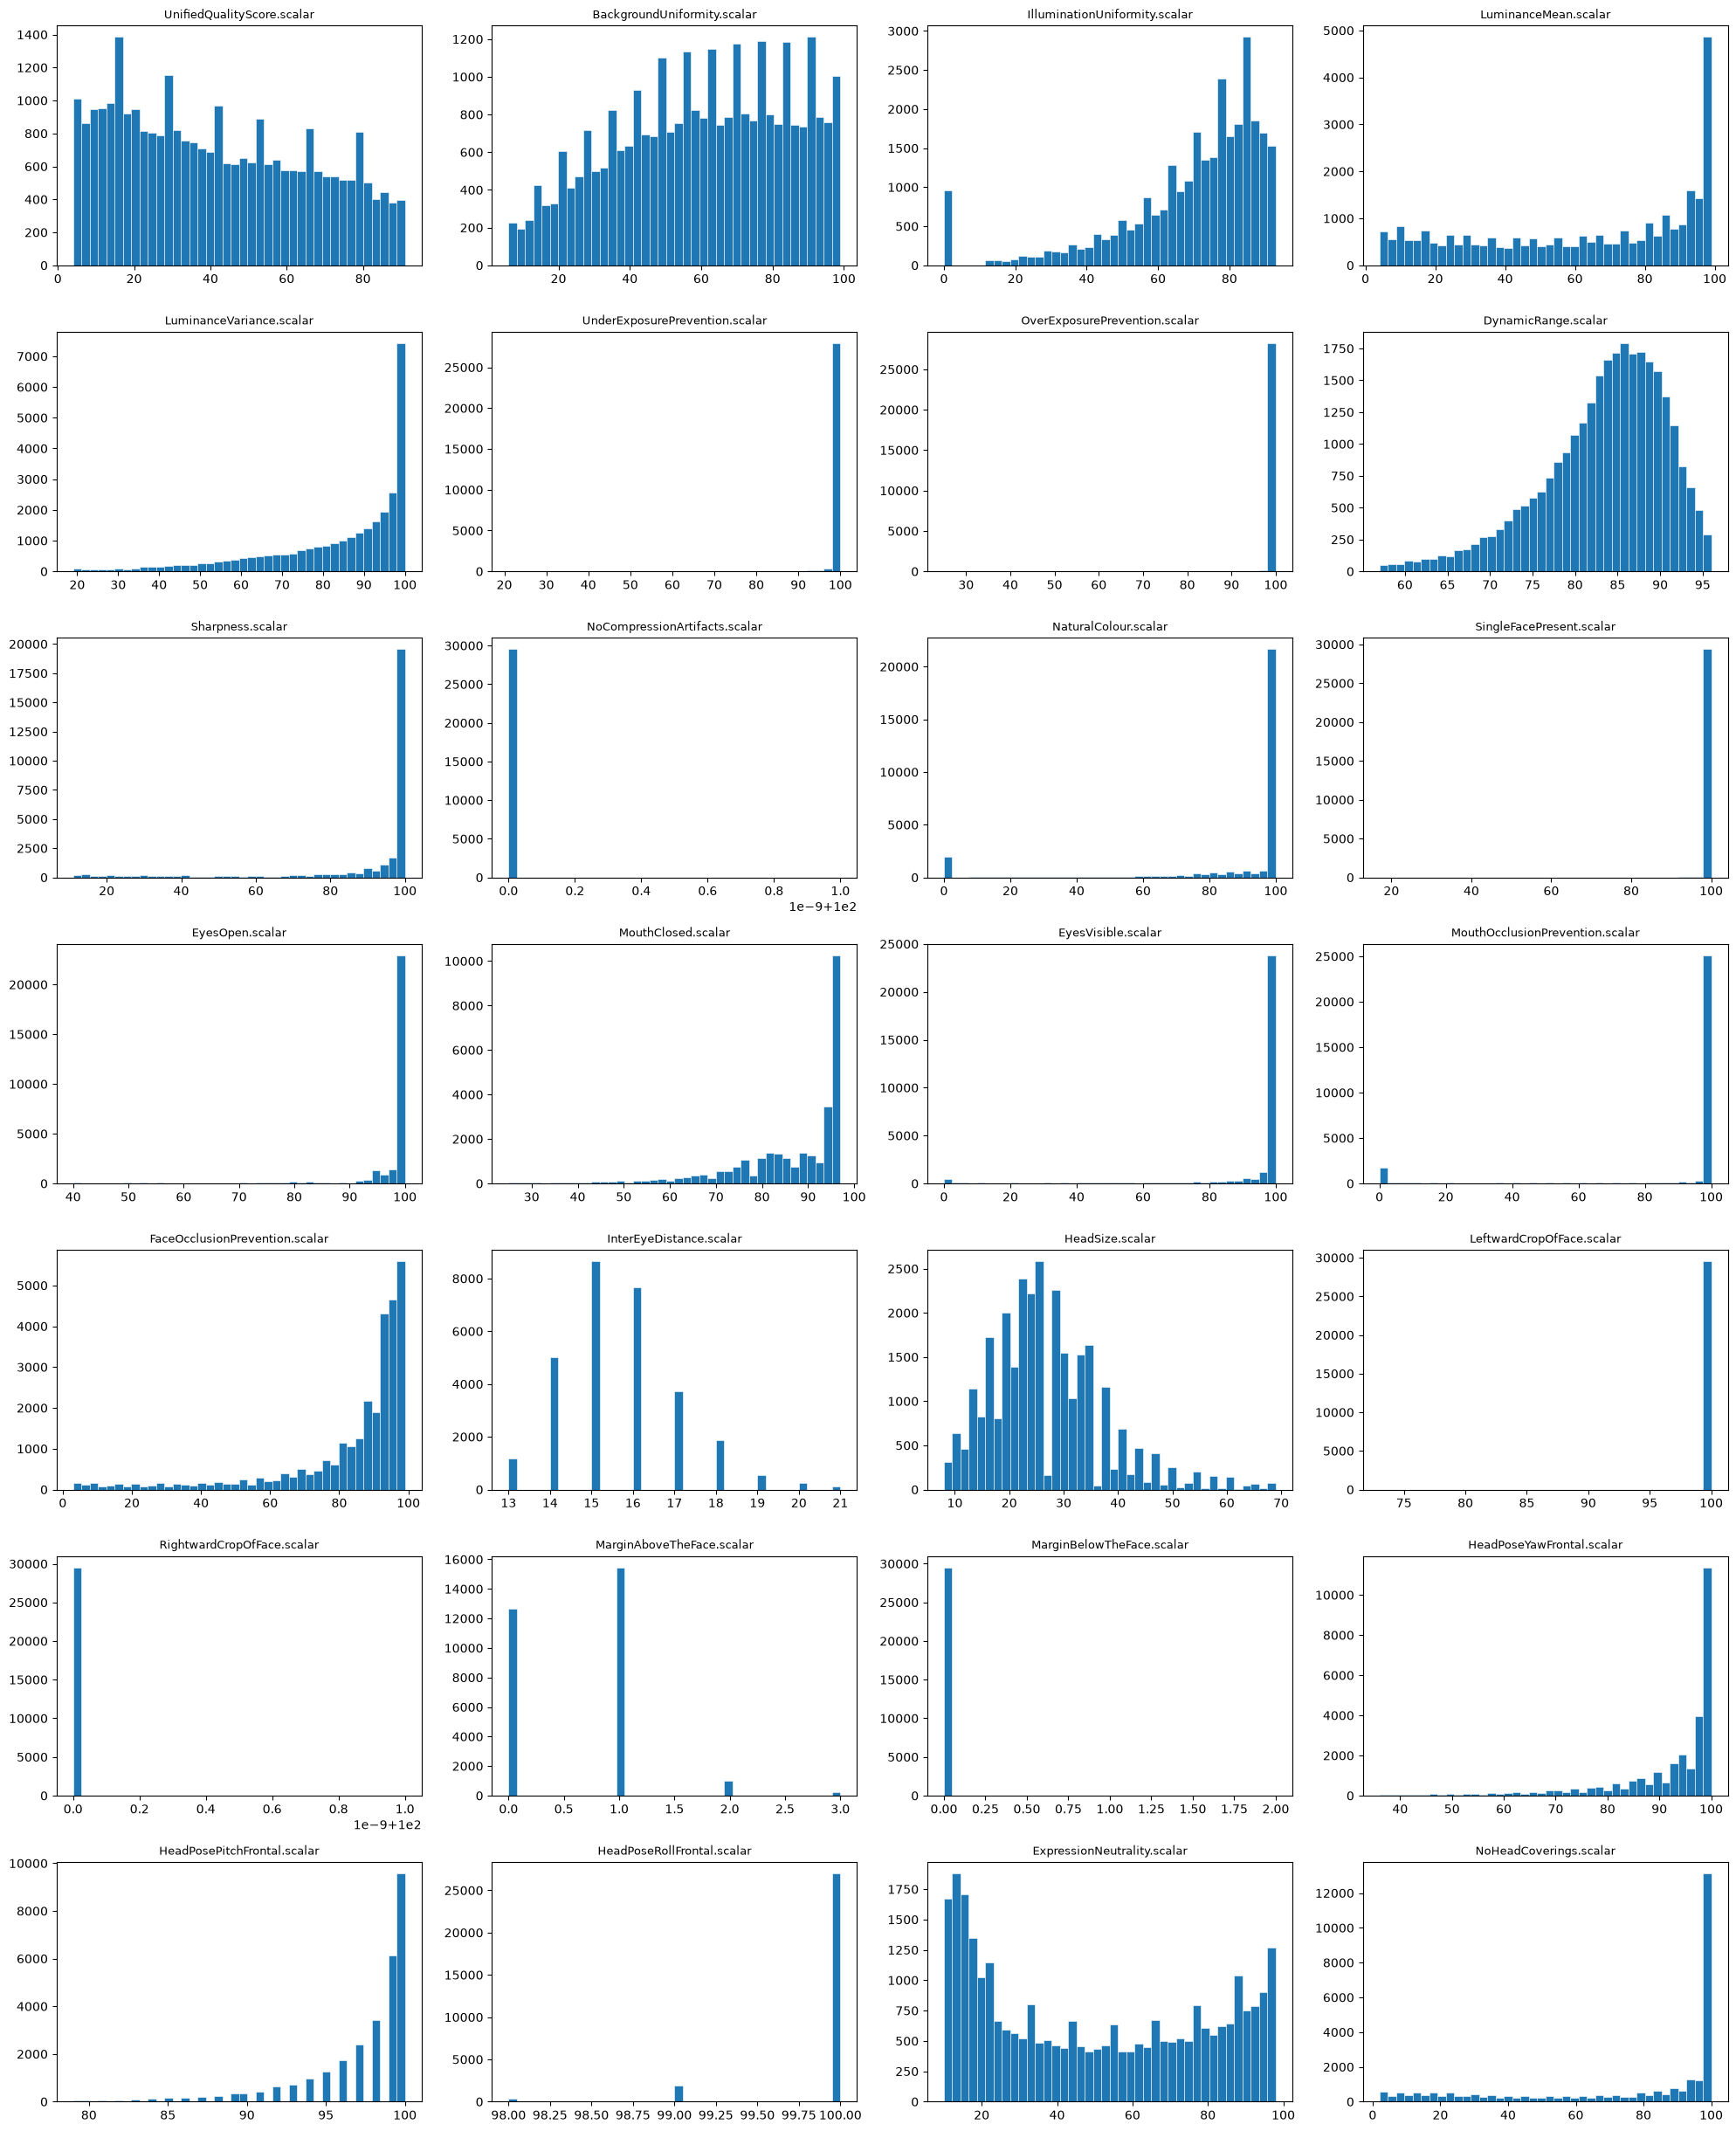

In [9]:
create_histograms(scalar);

There are columns that cannot be studied because they reach saturation.

Most of these histograms show repetitive pattern, peak at the max value with a skew on the left, with only few exception with peak at the minimum value but often followed with another peak with less height.

This shows that a dataset with 200 images can't put a good distribution for each one of the features, it can be solved by adding more inputs or without using scalar values and go straight to the .native values.

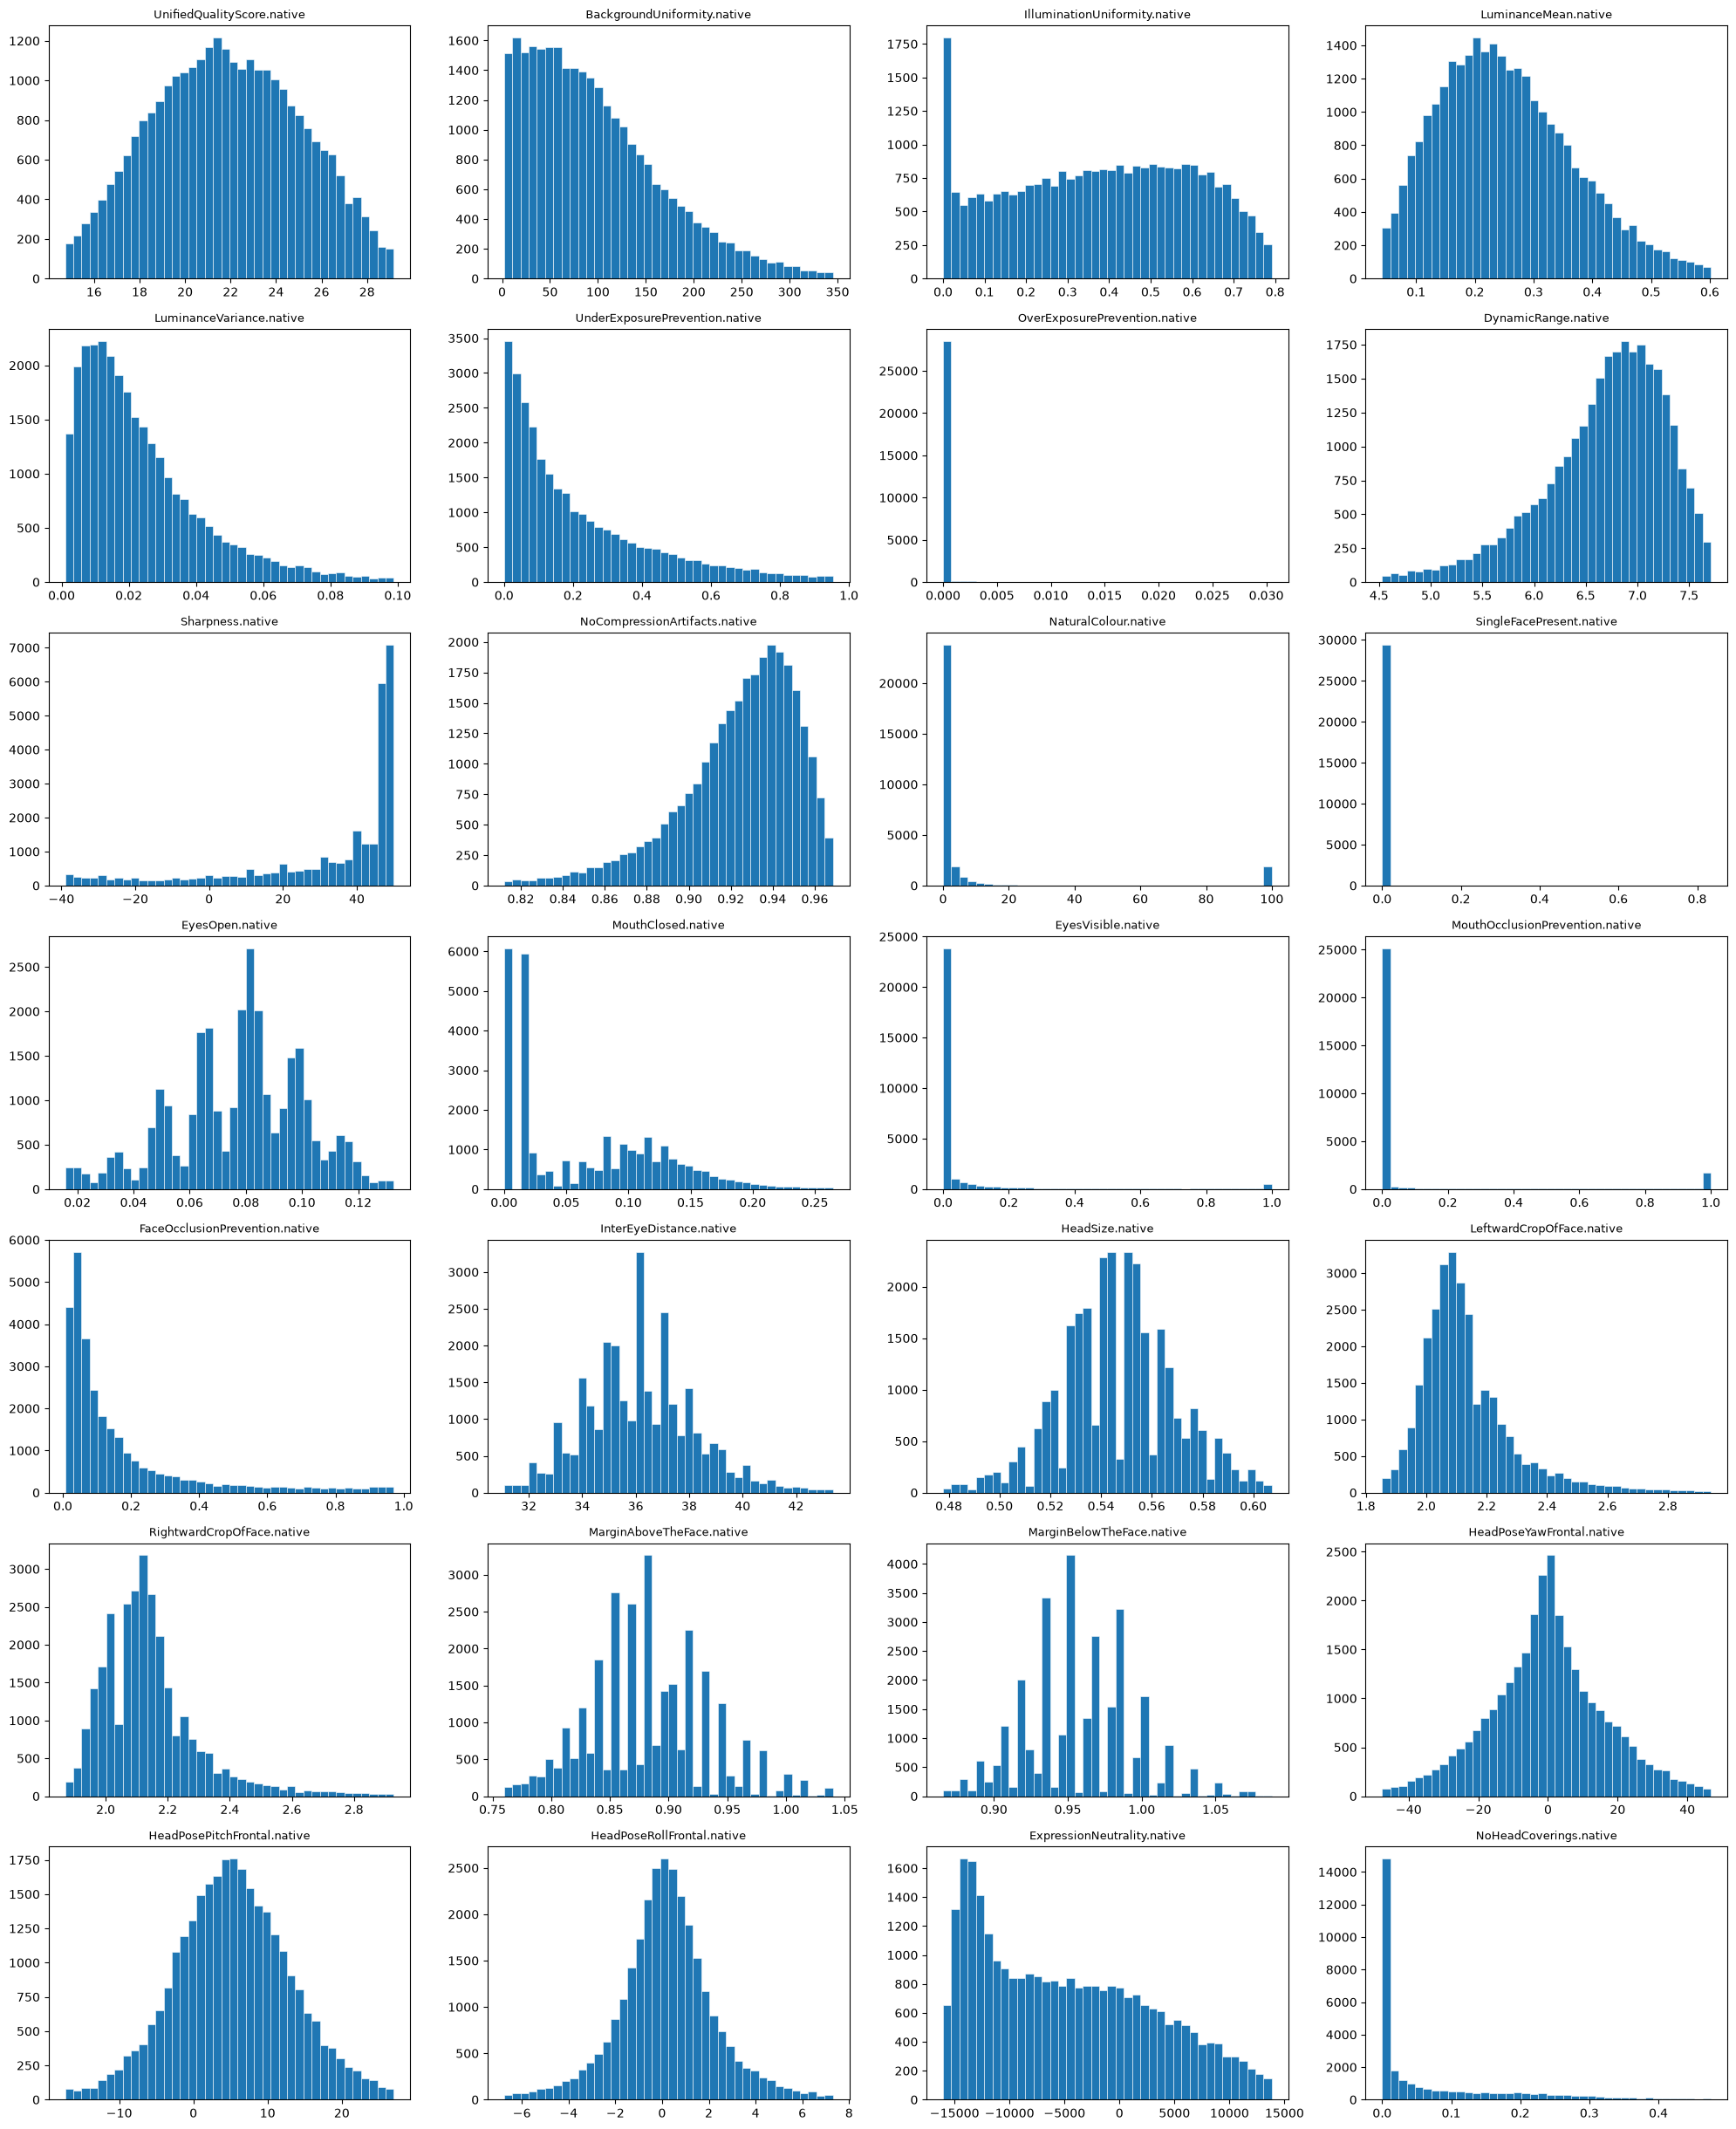

In [10]:
create_histograms(native);

With the .native DataFrame we cen see different type if distribution in comparison of the .scalar dataframe. 
9 out of the 28 columns shows peak near the min value of the feature with a right skew, but rather it is optimal for the other features that have much stronger distribution of datas.

We will continue the data exploration with the .native.

#### Mean and Variabilty of the data

In [11]:
df_describe = native.describe()
mean = df_describe.filter(pl.col('statistic') == 'mean')
median = df_describe.filter(pl.col('statistic') == '50%')

In [12]:
df_describe

statistic,UnifiedQualityScore.native,BackgroundUniformity.native,IlluminationUniformity.native,LuminanceMean.native,LuminanceVariance.native,UnderExposurePrevention.native,OverExposurePrevention.native,DynamicRange.native,Sharpness.native,NoCompressionArtifacts.native,NaturalColour.native,SingleFacePresent.native,EyesOpen.native,MouthClosed.native,EyesVisible.native,MouthOcclusionPrevention.native,FaceOcclusionPrevention.native,InterEyeDistance.native,HeadSize.native,LeftwardCropOfFace.native,RightwardCropOfFace.native,MarginAboveTheFace.native,MarginBelowTheFace.native,HeadPoseYawFrontal.native,HeadPosePitchFrontal.native,HeadPoseRollFrontal.native,ExpressionNeutrality.native,NoHeadCoverings.native
str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""count""",29569.0,29569.0,29569.0,29569.0,29569.0,29569.0,29569.0,29569.0,29569.0,29569.0,29569.0,29569.0,29569.0,29569.0,29569.0,29569.0,29569.0,29569.0,29569.0,29569.0,29569.0,29569.0,29569.0,29569.0,29569.0,29569.0,29569.0,29569.0
"""null_count""",0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
"""mean""",21.821016,99.605201,0.382258,0.256323,0.0244,0.224912,0.001527,6.661112,30.443539,0.922053,7.532266,0.001027,0.077377,0.069388,0.061319,0.094724,0.173808,36.194755,0.545953,2.138266,2.148401,0.882345,0.956701,-0.370293,5.283962,0.189312,-4721.010837,0.074816
"""std""",3.44668,77.869675,0.223857,0.123044,0.020515,0.223087,0.019262,0.682837,24.8213,0.043023,24.598215,0.01958,0.02482,0.066514,0.186596,0.268242,0.216786,2.94831,0.030323,0.215538,0.214925,0.063124,0.051911,18.192953,8.595737,2.592295,8031.666447,0.114842
"""min""",0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,-48.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,-84.547055,-57.744731,-46.807667,-18355.724609,0.0
"""25%""",19.3585,41.353096,0.198242,0.165812,0.0101,0.055918,0.0,6.342551,20.0,0.908796,0.0,0.0,0.06341,0.015992,0.0,0.0,0.041342,34.844377,0.531419,2.027027,2.042983,0.848939,0.933543,-10.601471,0.05752,-0.971055,-12072.885742,0.0
"""50%""",21.774485,84.1688,0.391582,0.241549,0.018872,0.145933,0.0,6.780847,43.0,0.929257,0.0,0.0,0.080136,0.061062,0.0,0.0,0.085074,36.056642,0.5451,2.09095,2.113423,0.883211,0.951489,-0.360262,5.158611,0.162088,-5818.027832,0.011773
"""75%""",24.2813,139.172018,0.567901,0.33087,0.032335,0.327905,0.0,7.123106,47.0,0.94467,0.919026,0.0,0.095,0.116088,0.005514,0.0,0.200978,37.390366,0.562518,2.1875,2.207506,0.915254,0.982787,9.656827,10.501759,1.324414,1281.199951,0.115217
"""max""",33.42672,1360.718299,1.0,0.920304,0.192366,1.0,1.0,7.968862,50.0,0.985904,100.0,0.834659,0.295233,0.529605,1.0,1.0,0.999951,152.225076,0.679291,10.166667,9.5,1.453911,1.418555,84.25741,54.40643,64.840284,19458.347656,0.899911


In [13]:
mean

statistic,UnifiedQualityScore.native,BackgroundUniformity.native,IlluminationUniformity.native,LuminanceMean.native,LuminanceVariance.native,UnderExposurePrevention.native,OverExposurePrevention.native,DynamicRange.native,Sharpness.native,NoCompressionArtifacts.native,NaturalColour.native,SingleFacePresent.native,EyesOpen.native,MouthClosed.native,EyesVisible.native,MouthOcclusionPrevention.native,FaceOcclusionPrevention.native,InterEyeDistance.native,HeadSize.native,LeftwardCropOfFace.native,RightwardCropOfFace.native,MarginAboveTheFace.native,MarginBelowTheFace.native,HeadPoseYawFrontal.native,HeadPosePitchFrontal.native,HeadPoseRollFrontal.native,ExpressionNeutrality.native,NoHeadCoverings.native
str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""mean""",21.821016,99.605201,0.382258,0.256323,0.0244,0.224912,0.001527,6.661112,30.443539,0.922053,7.532266,0.001027,0.077377,0.069388,0.061319,0.094724,0.173808,36.194755,0.545953,2.138266,2.148401,0.882345,0.956701,-0.370293,5.283962,0.189312,-4721.010837,0.074816


In [14]:
median

statistic,UnifiedQualityScore.native,BackgroundUniformity.native,IlluminationUniformity.native,LuminanceMean.native,LuminanceVariance.native,UnderExposurePrevention.native,OverExposurePrevention.native,DynamicRange.native,Sharpness.native,NoCompressionArtifacts.native,NaturalColour.native,SingleFacePresent.native,EyesOpen.native,MouthClosed.native,EyesVisible.native,MouthOcclusionPrevention.native,FaceOcclusionPrevention.native,InterEyeDistance.native,HeadSize.native,LeftwardCropOfFace.native,RightwardCropOfFace.native,MarginAboveTheFace.native,MarginBelowTheFace.native,HeadPoseYawFrontal.native,HeadPosePitchFrontal.native,HeadPoseRollFrontal.native,ExpressionNeutrality.native,NoHeadCoverings.native
str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""50%""",21.774485,84.1688,0.391582,0.241549,0.018872,0.145933,0.0,6.780847,43.0,0.929257,0.0,0.0,0.080136,0.061062,0.0,0.0,0.085074,36.056642,0.5451,2.09095,2.113423,0.883211,0.951489,-0.360262,5.158611,0.162088,-5818.027832,0.011773


In [15]:
for c1, c2 in zip(mean.columns, median.columns):
    print(f"Column {c1}")
    print(f"Mean: {mean[c1].to_numpy().item()}")
    print(f"Median: {median[c1].to_numpy().item()}")
    print("==============")

Column statistic
Mean: mean
Median: 50%
Column UnifiedQualityScore.native
Mean: 21.821015829821775
Median: 21.774485
Column BackgroundUniformity.native
Mean: 99.60520106435793
Median: 84.1688
Column IlluminationUniformity.native
Mean: 0.3822579194764787
Median: 0.391582
Column LuminanceMean.native
Mean: 0.2563229866075958
Median: 0.241549
Column LuminanceVariance.native
Mean: 0.024400023842537793
Median: 0.018872
Column UnderExposurePrevention.native
Mean: 0.2249117884947073
Median: 0.145933
Column OverExposurePrevention.native
Mean: 0.0015265068822077174
Median: 0.0
Column DynamicRange.native
Mean: 6.661111712300044
Median: 6.780847
Column Sharpness.native
Mean: 30.443538841354123
Median: 43.0
Column NoCompressionArtifacts.native
Mean: 0.9220530929689876
Median: 0.929257
Column NaturalColour.native
Mean: 7.532265627312387
Median: 0.0
Column SingleFacePresent.native
Mean: 0.0010267693530386552
Median: 0.0
Column EyesOpen.native
Mean: 0.0773771848557611
Median: 0.080136
Column MouthClos

In [16]:
distance = df_describe.select(
    cs.numeric().filter(pl.col("statistic") == "max").first()
    - cs.numeric().filter(pl.col("statistic") == "min").first()
)

for col in distance.columns:
    print(col)
    print(f"Distanza: {distance[col].to_numpy().item()}")
    print("============")

UnifiedQualityScore.native
Distanza: 33.42672
BackgroundUniformity.native
Distanza: 1360.718299
IlluminationUniformity.native
Distanza: 1.0
LuminanceMean.native
Distanza: 0.920304
LuminanceVariance.native
Distanza: 0.192366
UnderExposurePrevention.native
Distanza: 1.0
OverExposurePrevention.native
Distanza: 1.0
DynamicRange.native
Distanza: 7.968862
Sharpness.native
Distanza: 98.0
NoCompressionArtifacts.native
Distanza: 0.985904
NaturalColour.native
Distanza: 100.0
SingleFacePresent.native
Distanza: 0.834659
EyesOpen.native
Distanza: 0.295233
MouthClosed.native
Distanza: 0.529605
EyesVisible.native
Distanza: 1.0
MouthOcclusionPrevention.native
Distanza: 1.0
FaceOcclusionPrevention.native
Distanza: 0.999951
InterEyeDistance.native
Distanza: 152.225076
HeadSize.native
Distanza: 0.679291
LeftwardCropOfFace.native
Distanza: 10.166667
RightwardCropOfFace.native
Distanza: 9.5
MarginAboveTheFace.native
Distanza: 1.453911
MarginBelowTheFace.native
Distanza: 1.418555
HeadPoseYawFrontal.native
D

In [17]:
std = df_describe.filter(pl.col('statistic') == 'std')

for col in std.columns:
    print(col)
    print(f"Varianza: {std[col].to_numpy().item()}")
    print("========================")

statistic
Varianza: std
UnifiedQualityScore.native
Varianza: 3.4466800028286206
BackgroundUniformity.native
Varianza: 77.86967502693788
IlluminationUniformity.native
Varianza: 0.22385650758027004
LuminanceMean.native
Varianza: 0.12304372499538943
LuminanceVariance.native
Varianza: 0.02051469919005479
UnderExposurePrevention.native
Varianza: 0.22308699541389654
OverExposurePrevention.native
Varianza: 0.01926245378532389
DynamicRange.native
Varianza: 0.6828373748673908
Sharpness.native
Varianza: 24.82129989968181
NoCompressionArtifacts.native
Varianza: 0.043023241371794266
NaturalColour.native
Varianza: 24.59821521357289
SingleFacePresent.native
Varianza: 0.019580237223147348
EyesOpen.native
Varianza: 0.024820057542054196
MouthClosed.native
Varianza: 0.0665137849571265
EyesVisible.native
Varianza: 0.186595778219709
MouthOcclusionPrevention.native
Varianza: 0.26824176167558594
FaceOcclusionPrevention.native
Varianza: 0.21678597221121954
InterEyeDistance.native
Varianza: 2.9483099658216103

Big range of datas:
- Sharpness.native --> Distance: 89.0
- BackgroundUniformity.native --> Distance: 394.722418
- ExpressionNeutrality.native --> Distance: 33017.516602

Variance:
- ExpressionNeutrality.native --> Variance: 8572.953698773426
- BackgroundUniformity.native --> Variance: 74.51952757612418
- NaturalColour.native --> Variance: 27.161944465058568

##### Percentili

In [18]:
def whisker_and_box_diagram(df):
    col = 4

    numeric_columns = [
        name for name in df.columns
        if df[name].dtype.is_numeric()
    ]
    row = math.ceil(len(numeric_columns) / col)
    fig, ax = plt.subplots(row, col, figsize=(20, 4 * row))
    ax = np.array(ax).flatten()

    for i, name in enumerate(numeric_columns):
        column = df[name].drop_nulls().to_numpy()

        if len(column) == 0:
            continue

        q1 = np.percentile(column, 25)
        med = np.percentile(column, 50)
        q3 = np.percentile(column, 75)

        iqr = q3 - q1

        lower_limit = q1 - 1.5 * iqr
        upper_limit = q3 + 1.5 * iqr

        fliers = column[
            (column < lower_limit) | (column > upper_limit)
        ]

        whislo = np.min(column[column >= lower_limit])
        whishi = np.max(column[column <= upper_limit])

        plt_data = [{
            'label': "",
            'whislo': whislo,
            'q1': q1,
            'med': med,
            'q3': q3,
            'whishi': whishi,
            'fliers': fliers
        }]

        ax[i].bxp(plt_data, orientation="horizontal")
        ax[i].set_title(name)
    for i in range(len(numeric_columns), len(ax)):
        fig.delaxes(ax[i])
    plt.show()

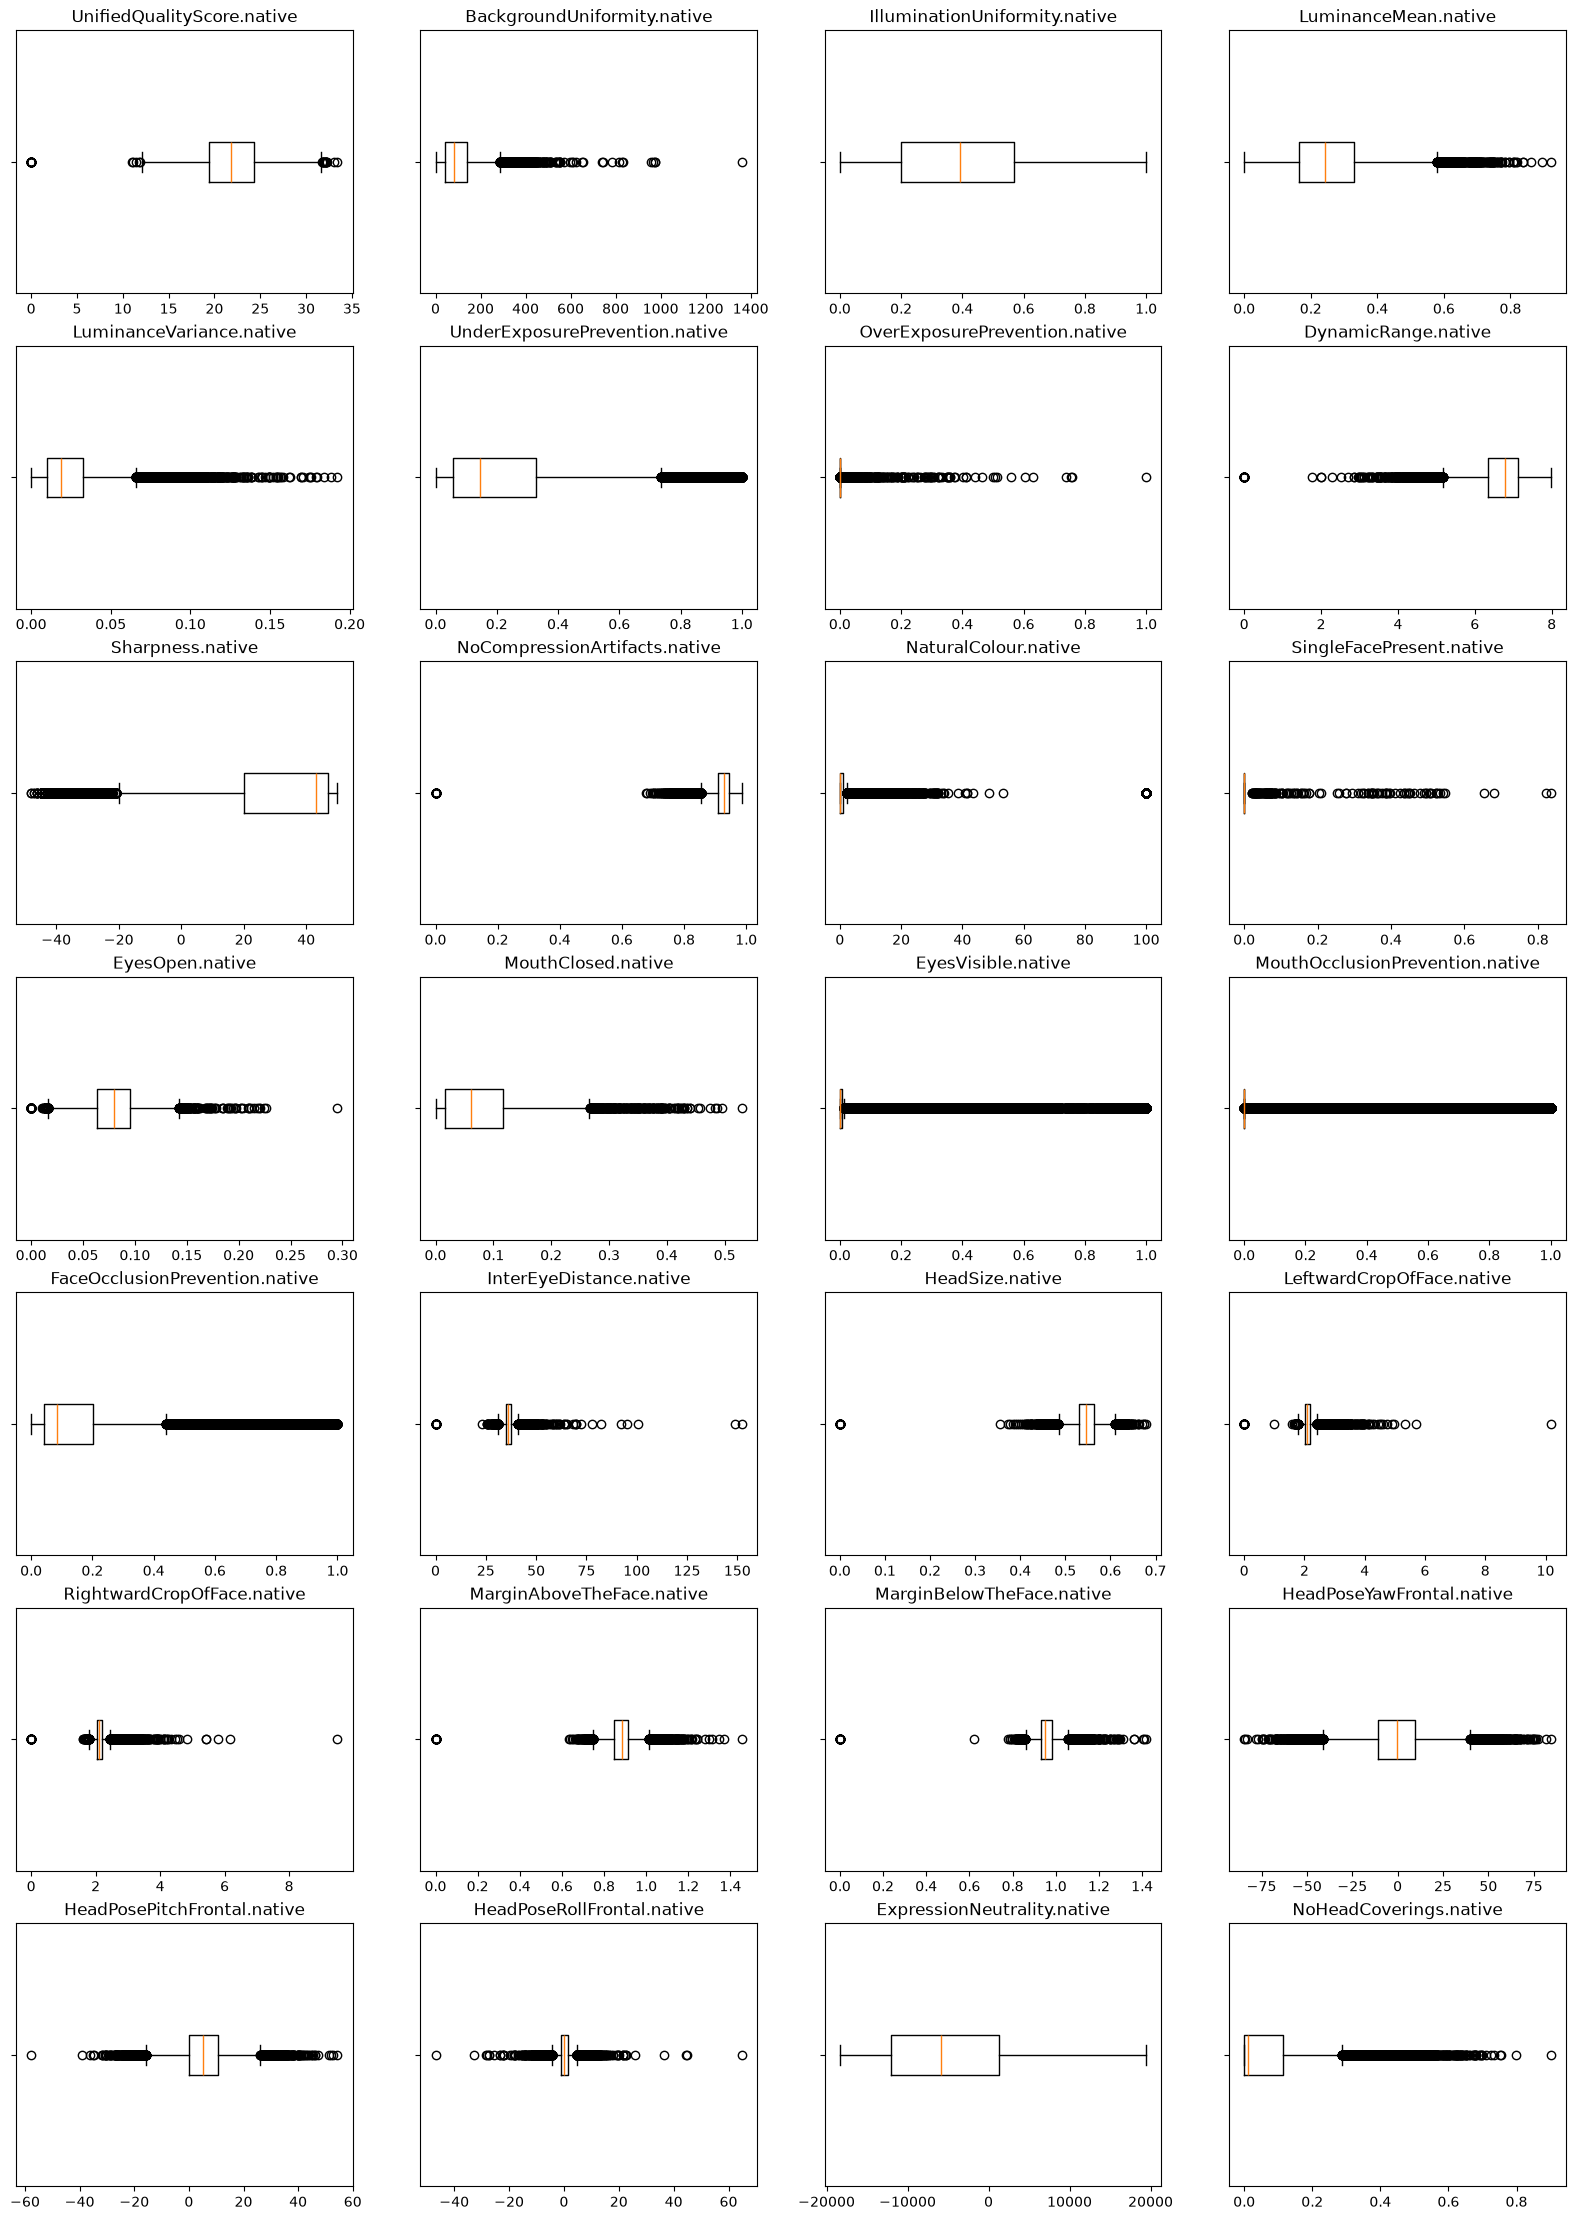

In [19]:
whisker_and_box_diagram(native)

#### Eventuali correlazioni

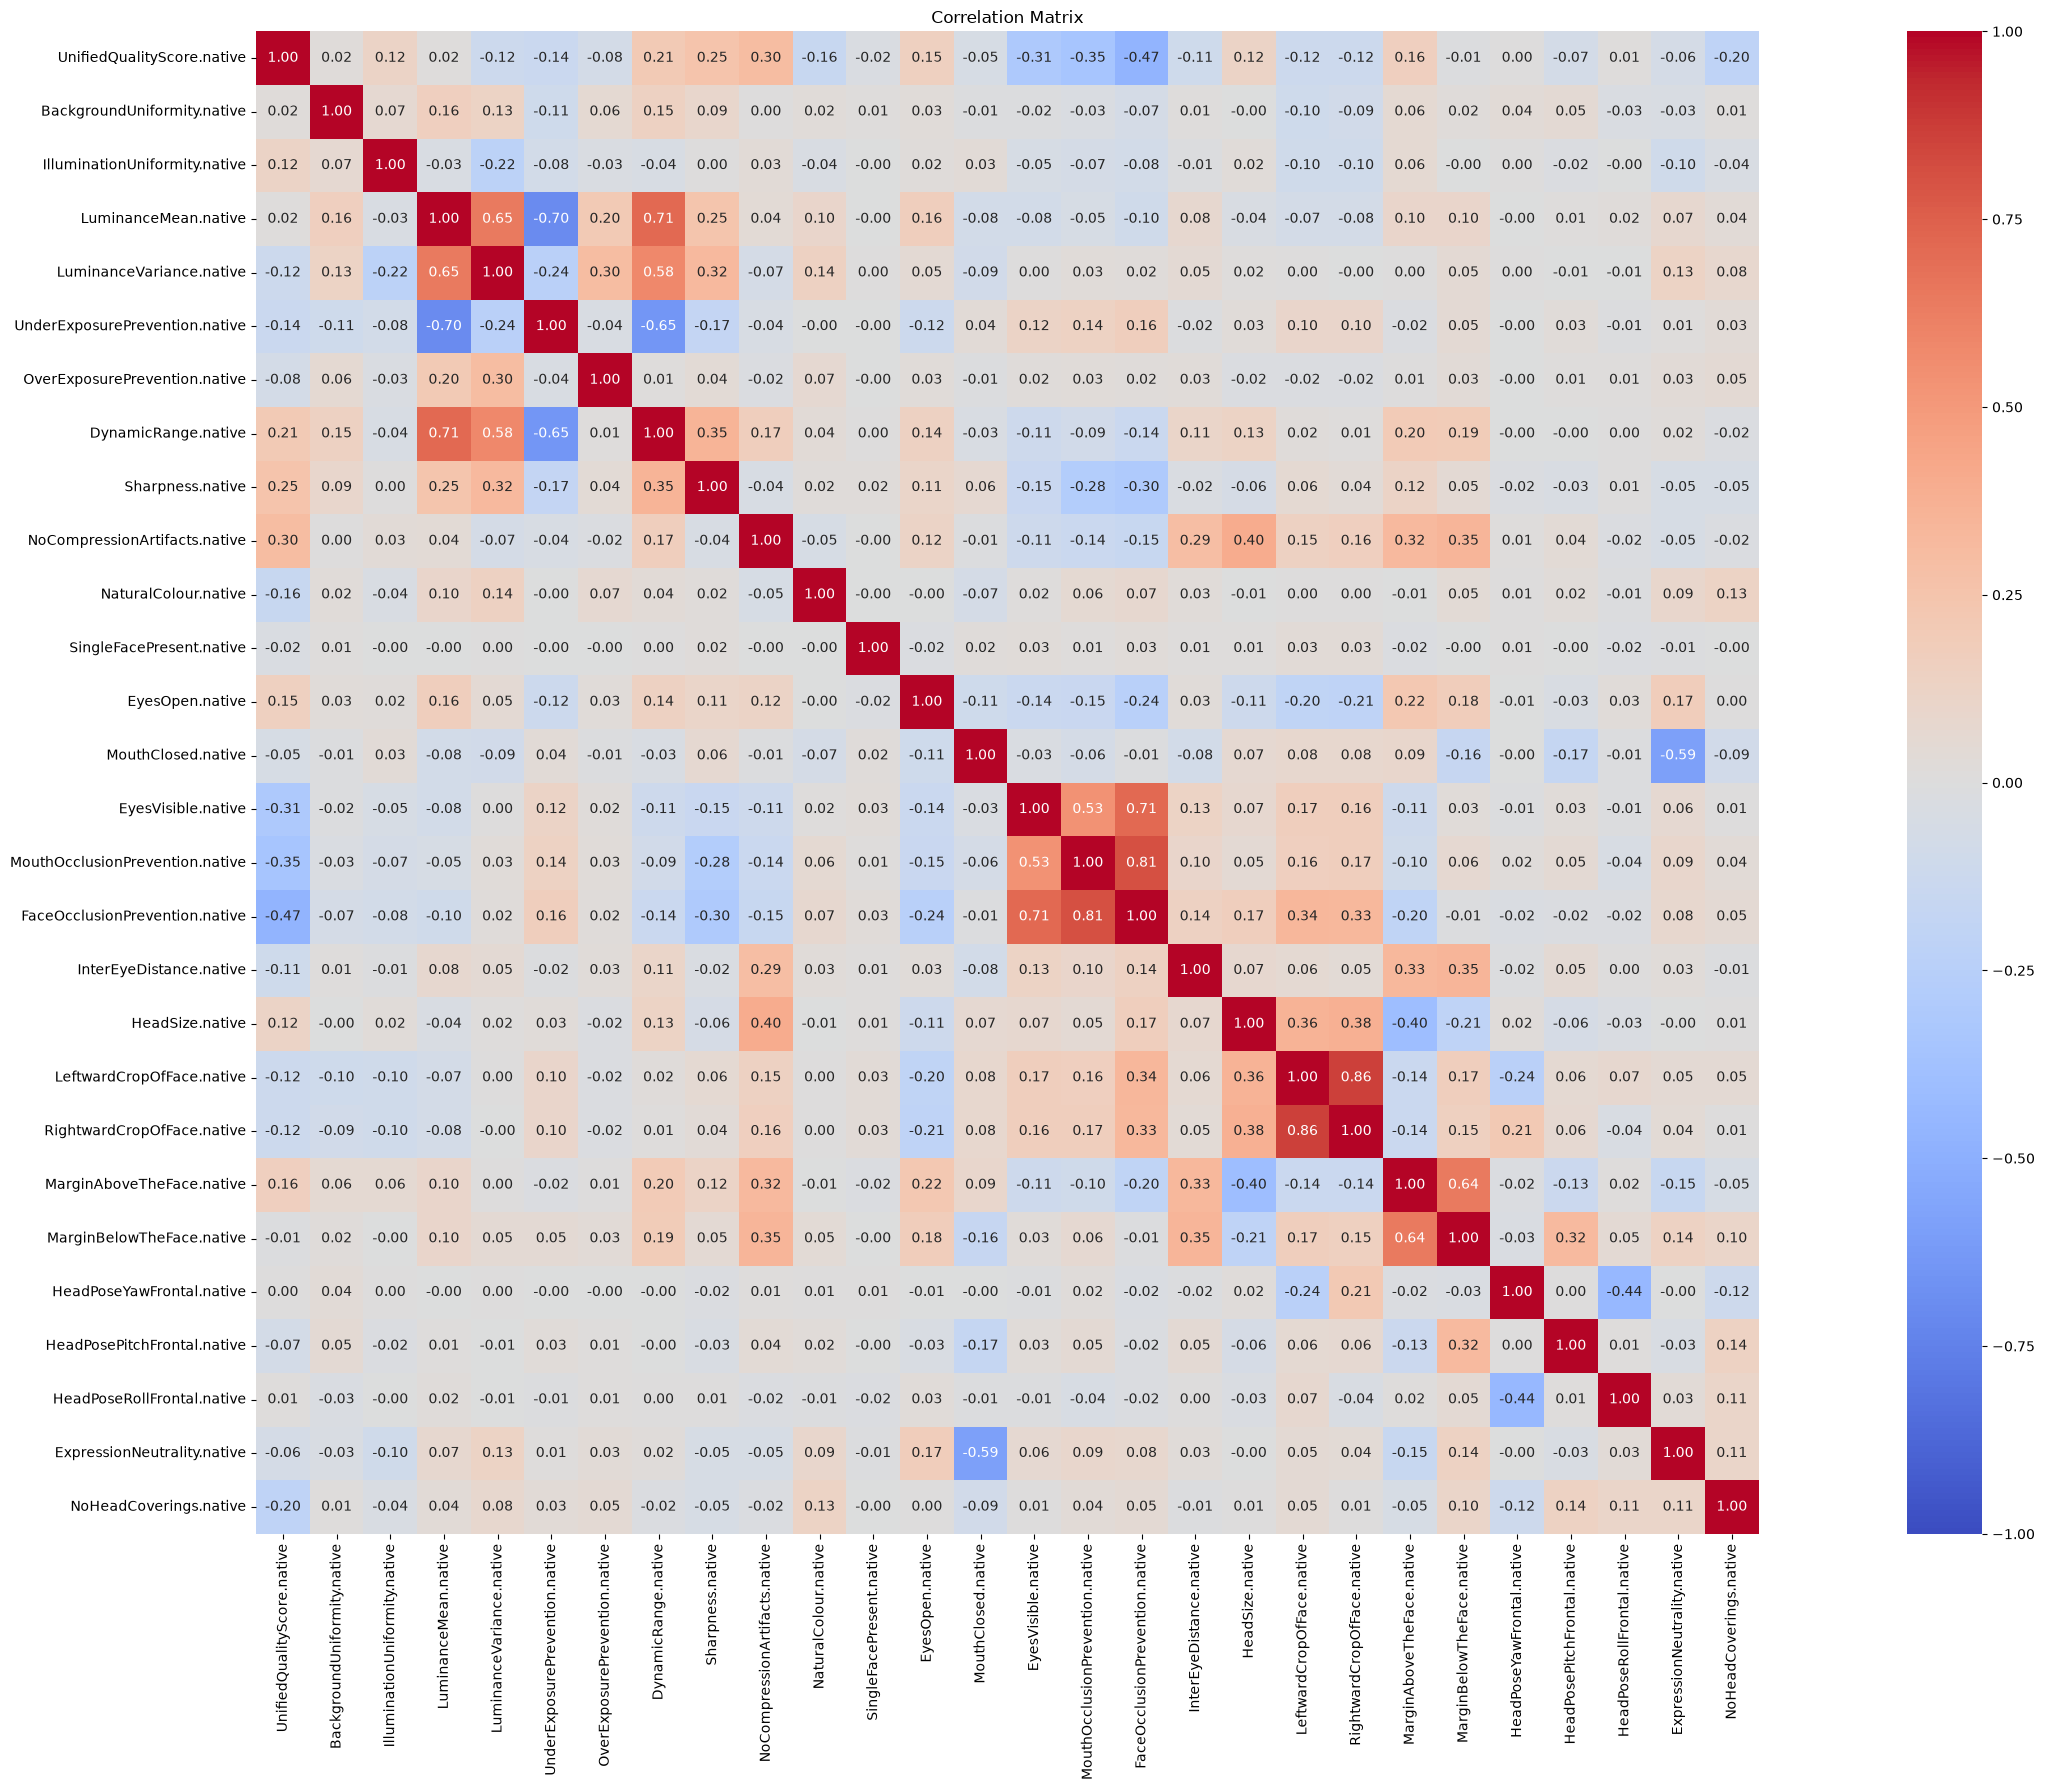

In [20]:
num_df = native.select(cs.numeric())
corr_df = num_df.corr()

corr_pd = corr_df.to_pandas()
corr_pd.index = corr_pd.columns   # le righe prendono i nomi delle colonne

plt.figure(figsize=(30, 18))
sns.heatmap(
    corr_pd,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1, vmax=1,
    square=True,
)
plt.title("Correlation Matrix")
plt.tight_layout()
plt.show()